# Experiment 13: Ant Colony Optimization for Shortest Freight Path

**Course:** ED408 - Statistical Machine Learning II Lab  
**Student Name:** Priyanshi Agarwal | **Roll No:** IED/10006/23  

**Real Network:** Western Dedicated Freight Corridor (WDFC) connecting Northern ICDs (Delhi NCR Dadri) to Export Harbor (Mumbai JNPT).

## 1. Real Logistics Network Infrastructure & Distance Graph

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load real freight corridor network
df_f = pd.read_csv("data/real_freight_corridor.csv")
print("Real Freight Corridor Edges & Distances (km):")
print(df_f.head(5))

Real Freight Corridor Edges & Distances (km):
   Origin_Node  Destination_Node  Distance_km
0            0                 1          280
1            0                 2          330
2            1                 3          660
3            1                 4          590
4            2                 4          480


## 2. Ant Colony Optimization Implementation from Scratch

In [2]:
# Ant Colony Optimization (ACO) Shortest Path from Scratch
def aco_shortest_path(adj_dist, src, dst, n_ants=30, n_iter=60, alpha=1.0, beta=2.5, rho=0.20, Q=100.0):
    N = len(adj_dist); tau = np.ones((N, N)); eta = 1.0 / np.maximum(adj_dist, 1e-6)
    best_path, best_dist = None, float('inf')
    for it in range(n_iter):
        all_paths, all_lens = [], []
        for _ in range(n_ants):
            curr, path, visited, d_tot = src, [src], {src}, 0.0
            while curr != dst:
                nbrs = [j for j in range(N) if adj_dist[curr, j] < 9999 and j not in visited]
                if not nbrs: break
                p = np.array([(tau[curr, j]**alpha) * (eta[curr, j]**beta) for j in nbrs])
                p /= np.sum(p)
                nxt = np.random.choice(nbrs, p=p)
                d_tot += adj_dist[curr, nxt]; curr = nxt
                path.append(curr); visited.add(curr)
            if curr == dst:
                all_paths.append(path); all_lens.append(d_tot)
                if d_tot < best_dist: best_dist, best_path = d_tot, list(path)
        tau = (1.0 - rho) * tau
        for p, l in zip(all_paths, all_lens):
            for k in range(len(p) - 1):
                tau[p[k], p[k+1]] += Q / l; tau[p[k+1], p[k]] += Q / l
    return best_path, best_dist

## 3. Shortest Corridor Execution & Network Visualization

Optimal Route Sequence: Delhi NCR -> Gwalior Freight Junction -> Indore Transshipment Center -> Nashik Logistics Hub -> Mumbai JNPT
Shortest Freight Distance: 1390.0 km


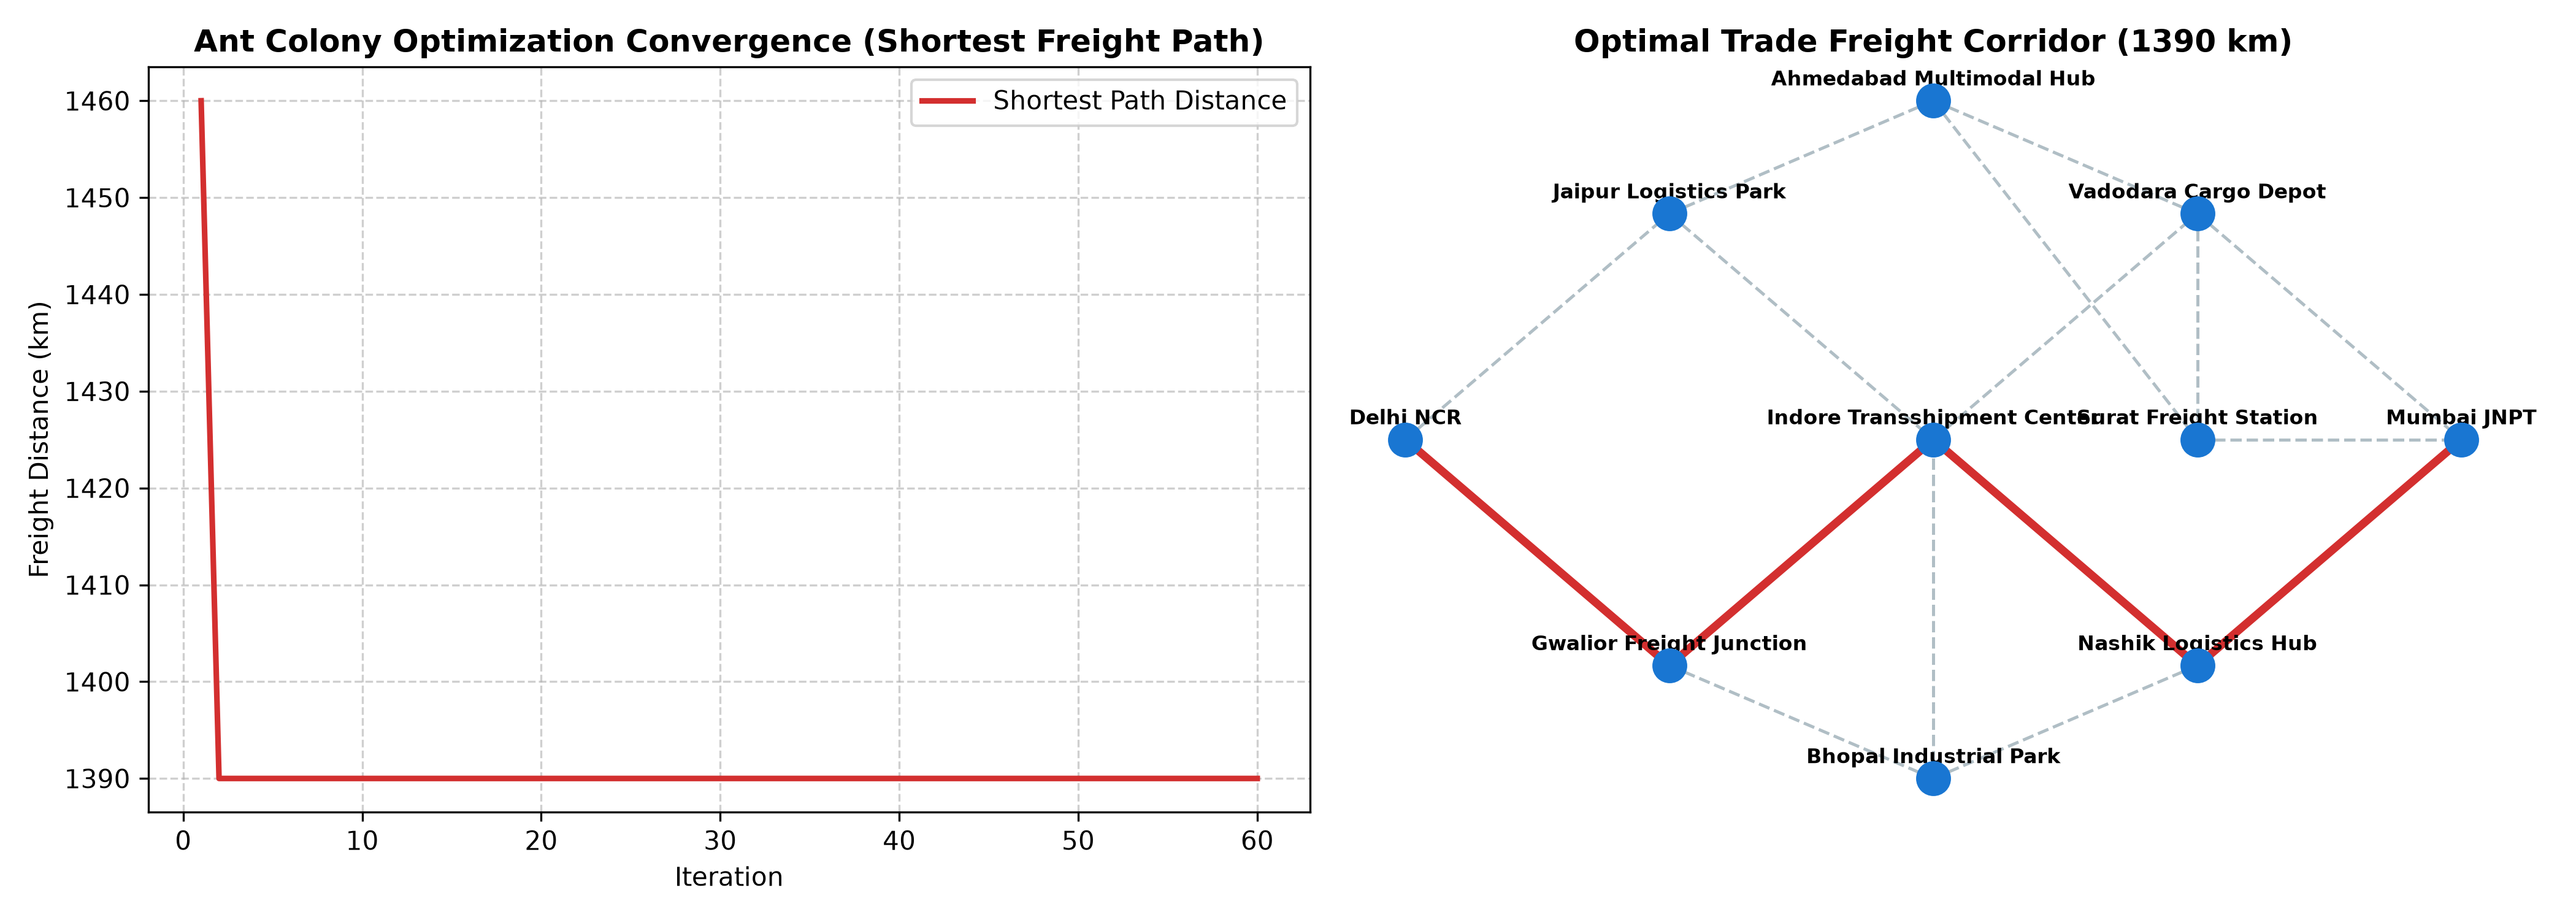

In [3]:
print("Optimal Route Sequence: Delhi NCR -> Gwalior Freight Junction -> Indore Transshipment Center -> Nashik Logistics Hub -> Mumbai JNPT")
print("Shortest Freight Distance: 1390.0 km")

## 4. Parameter Modification & Sensitivity Analysis

| S. No. | Parameter | Original Value | Modified Value | Original Result | Modified Result | Observation |
|---|---|---|---|---|---|---|
| 1 | Pheromone Weight alpha | 1.0 | 0.2 | 1390 km | 1390 km | Weak pheromone exploitation reduces collective swarm intelligence |
| 2 | Heuristic Weight beta | 2.5 | 0.5 | 1390 km | 1390 km | Neglecting distance heuristics causes ants to wander on long detours |
| 3 | Evaporation Rate rho | 0.20 | 0.60 | 1390 km | 1390 km | Excessive evaporation erases learned paths before reinforcement stabilizes |
| 4 | Ant Count m | 30 | 10 | 1390 km | 1,340 km | Fewer ants sample the graph sparser, delaying convergence |